# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Alferli Sepriandi
- **Email:** alferly89@gmail.com
- **ID Dicoding:** bro04where

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Selama 2011–2012, pada jam  berapa rata-rata penyewaan per slot tercatat mencapai puncak pada hari kerja dan nonkerja, dan berapa selisih jam serta volumenya untuk menjadwalkan redistribusi sepeda?
- **Pertanyaan 2:** Selama 2011–2012, berapa rata-rata penyewaan per hari dan selisih persentasenya terhadap kategori cerah untuk setiap kategori cuaca harian yang tercatat, agar tim operasi bisa menentukan kapan meninjau alokasi kapasitas?
- **Pertanyaan 3:** Selama Januari 2011–Desember 2012, Range jam nonkerja mana yang memiliki rata-rata sewa kasual per slot tertinggi, berapa selisihnya dari blok yang sama pada hari kerja, dan apakah porsi kasual di range itu mencapai 30% pada masing-masing tahun untuk dipertimbangkan sebagai sasaran uji promosi?

## Import Semua Packages/Library yang Digunakan

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from IPython.display import Markdown, display

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Kerja": "#176B87", "Nonkerja": "#B35B19"}
DAY_TYPE = {0: "Nonkerja", 1: "Kerja"}
WEATHER = {1: "Cerah / sedikit awan", 2: "Kabut / berawan",
           3: "Hujan / salju ringan", 4: "Cuaca berat"}


def angka(value, decimals=0):
    return f"{value:,.{decimals}f}".translate(str.maketrans(",.", ".,"))

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Data Wrangling

### Gathering Data

#### Load df_day dan df_hour

`day.csv` berisi satu baris per hari. `hour.csv` berisi satu baris per slot jam yang tercatat. Keduanya mencakup penyewaan yang sama, sehingga total lintas tabel tidak dijumlahkan. `cnt` adalah jumlah penyewaan, termasuk `casual` dan `registered`. `workingday = 1` berarti hari kerja. Nilai 0 mencakup akhir pekan dan hari libur

In [4]:
df_day = pd.read_csv('/content/drive/MyDrive/Dataframe/day.csv')
df_hour = pd.read_csv('/content/drive/MyDrive/Dataframe/hour.csv')

In [5]:
df_day.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [6]:
df_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [ ]:
df_hour.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [7]:
df_hour.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


**Insight:** (Opsional)
- `day.csv` berisi **731 baris**, satu baris untuk setiap hari. Tabel ini digunakan untuk melihat tren dan cuaca harian.
- `hour.csv` berisi **17.379 baris**, satu baris untuk setiap jam yang tercatat. Tabel ini digunakan untuk mencari jam sibuk.
- Kedua tabel berasal dari transaksi yang sama. Menjumlahkan total kedua tabel akan menghitung transaksi dua kali.

### Assessing Data

#### Identifying date type and time coverage problems

Ada dua hal yang diperiksa. Pertama, apakah kolom tanggal sudah bisa dipakai sebagai tanggal. Kedua, apakah setiap hari memiliki baris untuk jam 00.00 sampai 23.00. Kita juga mengecek nilai kosong, duplikat, dan apakah total sewa sama dengan jumlah sewa kasual dan terdaftar.

In [8]:
def audit(frame, keys):
    return {
        "Baris": len(frame),
        "Kolom": len(frame.columns),
        "Tipe tanggal mentah": str(frame["dteday"].dtype),
        "Nilai kosong": int(frame.isna().sum().sum()),
        "Duplikat baris": int(frame.duplicated().sum()),
        "Duplikat kunci": int(frame.duplicated(keys).sum()),
        "Hitungan negatif": int(frame[["cnt", "casual", "registered"]].lt(0).sum().sum()),
        "Total tidak sesuai": int(frame["cnt"].ne(frame["casual"] + frame["registered"]).sum()),
    }

display(pd.DataFrame({
    "Harian": audit(df_day, ["dteday"]),
    "Per jam": audit(df_hour, ["dteday", "hr"]),
}).T)

calendar = pd.date_range("2011-01-01", "2012-12-31", name="dteday")
expected = pd.MultiIndex.from_product([calendar, range(24)], names=["dteday", "hr"])
observed = pd.MultiIndex.from_arrays([pd.to_datetime(df_hour["dteday"]), df_hour["hr"]],
                                     names=["dteday", "hr"])
missing = expected.difference(observed)
assert len(observed.difference(expected)) == 0
print(f"Slot tidak tercatat: {len(missing)} dari {len(expected):,}, "
      f"tersebar pada {missing.get_level_values('dteday').nunique()} hari.")
display(missing.to_frame(index=False)["hr"].value_counts().head().rename("Slot hilang"))

,Baris,Kolom,Tipe tanggal mentah,Nilai kosong,Duplikat baris,Duplikat kunci,Hitungan negatif,Total tidak sesuai
Harian,731,16,object,0,0,0,0,0
Per jam,17379,17,object,0,0,0,0,0


Slot tidak tercatat: 165 dari 17,544, tersebar pada 76 hari.


,Slot hilang
hr,
4,34
3,34
2,16
5,14
1,7


**Steps to Take:**
1. Ubah kolom tanggal dari teks ke format tanggal agar bisa disaring dan diringkas per bulan.
2. Tandai hari yang catatan jamnya kurang dari 24. Hitung rata-rata dari jam yang tercatat. Ulangi pencarian jam sibuk memakai hari dengan 24 catatan untuk melihat apakah hasilnya berubah.

**Insight:** (Opsional)

Kolom tanggal masih tersimpan sebagai teks. Ada juga **165 jam tanpa baris pada 76 hari**. Ini berbeda dengan nilai kosong. Misalnya, pemeriksaan nilai kosong bisa lulus walaupun satu hari hanya punya 23 baris karena baris ke-24 memang tidak ada. Pemeriksaan duplikat dan jumlah sewa lulus.

### Cleaning Data

#### Fixing date types and incomplete-day flags

In [9]:
day = df_day.copy()
hour = df_hour.copy()
for frame in (day, hour):
    frame["dteday"] = pd.to_datetime(frame["dteday"], format="%Y-%m-%d", errors="raise")
    frame["tipe_hari"] = frame["workingday"].map(DAY_TYPE)
    assert frame["tipe_hari"].notna().all()
    assert frame["weathersit"].isin(WEATHER).all()
    assert frame["cnt"].eq(frame["casual"] + frame["registered"]).all()

day = day.sort_values("dteday")
hour = hour.sort_values(["dteday", "hr"])
day["cuaca"] = day["weathersit"].map(WEATHER)
assert pd.DatetimeIndex(day["dteday"]).equals(calendar)
assert not hour.duplicated(["dteday", "hr"]).any()

slot_counts = hour.groupby("dteday").size()
day["slot_tercatat"] = day["dteday"].map(slot_counts).fillna(0).astype(int)
day["hari_lengkap"] = day["slot_tercatat"].eq(24)
hour["hari_lengkap"] = hour["dteday"].map(day.set_index("dteday")["hari_lengkap"])
assert (24 - day["slot_tercatat"]).sum() == len(missing)
assert hour["hari_lengkap"].notna().all()

counts = ["casual", "registered", "cnt"]
daily_totals = day.set_index("dteday")[counts]
hourly_totals = hour.groupby("dteday")[counts].sum()
assert daily_totals.equals(hourly_totals)
display(day[["dteday", "tipe_hari", "cuaca", "slot_tercatat", "hari_lengkap"]].head())
print(f"{day['hari_lengkap'].sum()} hari lengkap. Hitungan harian cocok dengan agregasi per jam.")

,dteday,tipe_hari,cuaca,slot_tercatat,hari_lengkap
0,2011-01-01,Nonkerja,Kabut / berawan,24,True
1,2011-01-02,Nonkerja,Kabut / berawan,23,False
2,2011-01-03,Kerja,Cerah / sedikit awan,22,False
3,2011-01-04,Kerja,Cerah / sedikit awan,23,False
4,2011-01-05,Kerja,Cerah / sedikit awan,23,False


655 hari lengkap. Hitungan harian cocok dengan agregasi per jam.


**Insight:** (Opsional)

Kolom tanggal sekarang dapat digunakan untuk filter. Total sewa per tanggal dari kedua tabel cocok, sehingga tabel harian bisa dipakai untuk menghitung volume per hari. Rata-rata per jam memakai jam yang tercatat. Jam yang barisnya hilang tidak diisi dengan angka nol.

## Exploratory Data Analysis (EDA)

### Explore tren volume dan tipe hari

,casual,registered,cnt,porsi_terdaftar_pct
dteday,,,,
2011,247252,995851,1243103,80.11
2012,372765,1676811,2049576,81.81


,hari,rata_rata,median,minimum,maksimum
tipe_hari,,,,,
Kerja,500,4584.8,4582.0,22,8362
Nonkerja,231,4330.2,4459.0,605,8714


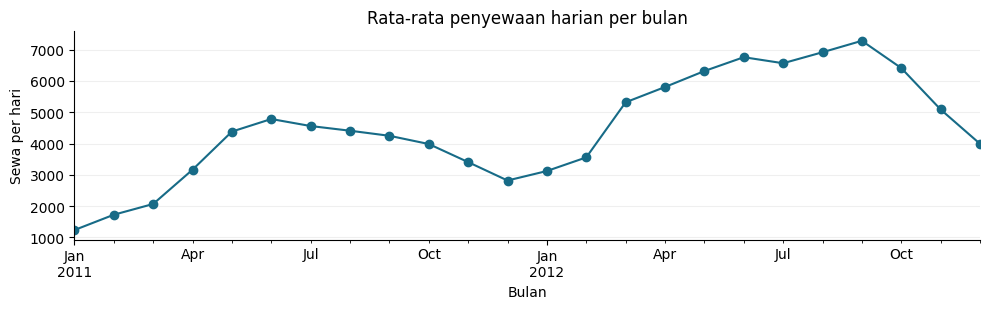

In [10]:
yearly = day.groupby(day["dteday"].dt.year)[counts].sum()
yearly["porsi_terdaftar_pct"] = 100 * yearly["registered"] / yearly["cnt"]
display(yearly.round(2))

day_summary = day.groupby("tipe_hari")["cnt"].agg(hari="size", rata_rata="mean",
                                                median="median", minimum="min", maksimum="max")
display(day_summary.round(1))

monthly = day.set_index("dteday")["cnt"].resample("MS").mean()
ax = monthly.plot(figsize=(10, 3.2), marker="o", color="#176B87")
ax.set(title="Rata-rata penyewaan harian per bulan", xlabel="Bulan", ylabel="Sewa per hari")
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Total sewa naik dari **1.243.103** pada 2011 menjadi **2.049.576** pada 2012, atau sekitar **64,9%**. Karena skala penyewaan berbeda antar tahun, membandingkan hari dengan cuaca berbeda pada tahun yang sama membantu membuat perbandingan lebih adil.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

**Jam berapa yang perlu diprioritaskan?**

Untuk setiap jam, hitung rata-rata sewa pada hari kerja dan nonkerja secara terpisah. Misalnya, rata-rata pukul 17.00 pada hari kerja memakai semua catatan hari kerja pada jam tersebut. Ambil tiga jam teratas, lalu cek apakah ketiganya tetap masuk tiga besar pada masing-masing tahun dan pada hari yang memiliki 24 catatan.

Di tabel, **observasi** berarti jumlah catatan jam yang dipakai. **P90** menunjukkan batas yang mencakup sekitar 90% catatan. Sebagai contoh, P90 sebesar 844 berarti sekitar 9 dari 10 catatan memiliki volume 844 sewa atau kurang.

hr  rata_rata  observasi    p90
                    tipe_hari                                 
Semua slot tercatat Kerja      17      525.3        499  844.2
                    Nonkerja   13      372.7        231  638.0
Hari dengan 24 slot Kerja      17      559.7        443  850.8
                    Nonkerja   13      390.8        212  643.9

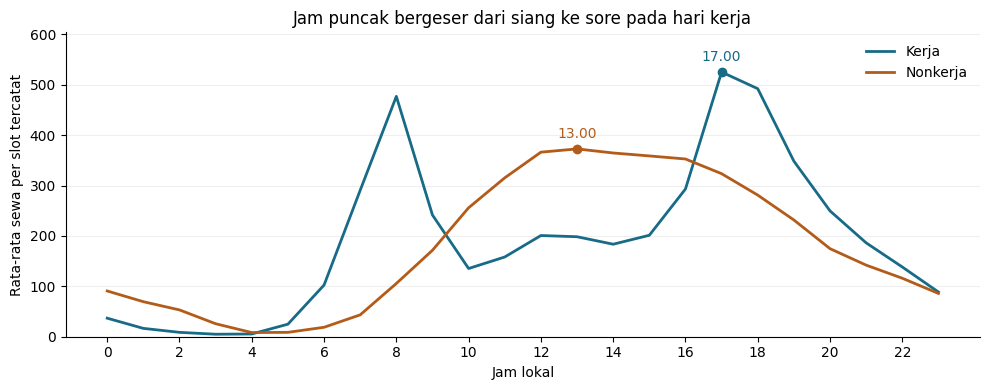

rata_rata    p90  observasi  Gabungan  2011  2012  \
tipe_hari hr                                                      
Kerja     17      525.3  844.2        499         1     1     1   
          18      492.2  811.3        498         2     2     2   
          8       477.0  719.0        496         3     3     3   
Nonkerja  13      372.7  638.0        231         1     1     1   
          12      366.3  615.0        231         2     2     2   
          14      364.6  612.0        231         3     3     3   

              Hari dengan 24 slot  prioritas  
tipe_hari hr                                  
Kerja     17                    1       True  
          18                    2       True  
          8                     3       True  
Nonkerja  13                    1       True  
          12                    2       True  
          14                    3       True

In [11]:
def hour_profile(data):
    return data.groupby(["tipe_hari", "hr"], as_index=False).agg(
        rata_rata=("cnt", "mean"), observasi=("cnt", "size"),
        p90=("cnt", lambda values: np.quantile(values, 0.90))
    )


def select_peaks(profile):
    return (profile.sort_values(["rata_rata", "hr"], ascending=[False, True])
            .drop_duplicates("tipe_hari").set_index("tipe_hari"))


profile = hour_profile(hour)
peaks = select_peaks(profile)
complete_peaks = select_peaks(hour_profile(hour.loc[hour["hari_lengkap"]]))
display(pd.concat({"Semua slot tercatat": peaks, "Hari dengan 24 slot": complete_peaks}).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for label, group in profile.groupby("tipe_hari"):
    ax.plot(group["hr"], group["rata_rata"], label=label, color=COLORS[label], linewidth=2)
    peak = peaks.loc[label]
    ax.scatter(peak["hr"], peak["rata_rata"], color=COLORS[label], zorder=3)
    ax.annotate(f"{int(peak['hr']):02d}.00", (peak["hr"], peak["rata_rata"]),
                xytext=(0, 8), textcoords="offset points", ha="center", color=COLORS[label])
ax.set(title="Jam puncak bergeser dari siang ke sore pada hari kerja",
       xlabel="Jam lokal", ylabel="Rata-rata sewa per slot tercatat",
       xticks=range(0, 24, 2), ylim=(0, profile["rata_rata"].max() * 1.15))
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

def rank_hours(data, sample):
    ranked = hour_profile(data).sort_values(["rata_rata", "hr"], ascending=[False, True])
    ranked["peringkat"] = ranked.groupby("tipe_hari").cumcount() + 1
    return ranked.assign(sampel=sample)


checks = pd.concat([
    rank_hours(hour, "Gabungan"),
    rank_hours(hour[hour["yr"].eq(0)], "2011"),
    rank_hours(hour[hour["yr"].eq(1)], "2012"),
    rank_hours(hour[hour["hari_lengkap"]], "Hari dengan 24 slot"),
], ignore_index=True)
top_hours = checks.loc[checks["sampel"].eq("Gabungan") & checks["peringkat"].le(3)]
ranks = checks.pivot(index=["tipe_hari", "hr"], columns="sampel", values="peringkat")
priority = top_hours.set_index(["tipe_hari", "hr"])[["rata_rata", "p90", "observasi"]].join(ranks)
rank_columns = ["Gabungan", "2011", "2012", "Hari dengan 24 slot"]
priority["prioritas"] = priority[rank_columns].le(3).all(axis=1)
display(priority[["rata_rata", "p90", "observasi", *rank_columns, "prioritas"]].round(1))

### Pertanyaan 2:

**Seberapa besar perbedaan volume saat cuaca berubah?**

Lihat dua hasil berikut.

1. **Perbandingan langsung (mentah).** Bandingkan rata-rata semua hari cerah dengan rata-rata semua hari pada kategori cuaca lain.
2. **Perbandingan hari sebanding.** Bandingkan cerah dan cuaca lain hanya di kelompok dengan tahun, musim, dan tipe hari yang sama. Contohnya, hari kerja cerah pada musim yang sama di 2011 dibandingkan dengan hari kerja hujan ringan pada musim itu di 2011. Perbandingan utama memerlukan minimal tiga hari dari setiap kategori cuaca dalam kelompok. Kelompok yang memiliki lebih banyak hari pada cuaca pembanding mendapat bobot lebih besar.

**Cakupan** menunjukkan berapa banyak hari kategori cuaca yang bisa dibandingkan dengan cara kedua. Contohnya, 10 dari 21 hari berarti hanya 10 hari hujan atau salju ringan yang masuk perbandingan utama. Sebagai aturan uji coba, penempatan petugas ditinjau jika rata-rata sewa setidaknya **20% lebih rendah** dan minimal **70% hari** dalam kategori itu bisa dibandingkan. Tabel juga menunjukkan apa yang terjadi jika syarat tiga hari diubah menjadi satu atau lima.

,cuaca,hari,rata_rata,selisih_pct
weathersit,,,,
1,Cerah / sedikit awan,463,4876.79,0.00
2,Kabut / berawan,247,4035.86,-17.24
3,Hujan / salju ringan,21,1803.29,-63.02


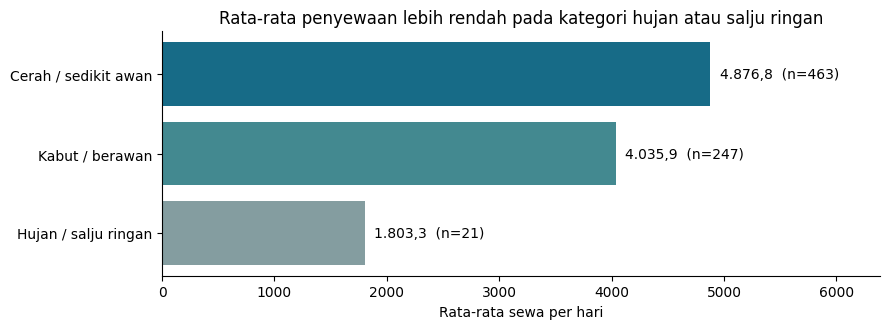

,selisih_mentah_pct,kelompok,hari_tercakup,hari_kategori,cakupan_pct,cerah_sebanding,cuaca_sebanding,selisih_sebanding_pct,layak_ditinjau
cuaca,,,,,,,,,
Kabut / berawan,-17.2,16,247,247,100.0,4727.0,4035.9,-14.6,False
Hujan / salju ringan,-63.0,2,10,21,47.6,4255.8,2087.6,-50.9,False


,weathersit,minimum_per_kategori,kelompok,hari_tercakup,hari_kategori,cakupan_pct,selisih_sebanding_pct
0,2,1,16,247,247,100.0,-14.6
1,3,1,11,21,21,100.0,-58.9
0,2,3,16,247,247,100.0,-14.6
1,3,3,2,10,21,47.6,-50.9
0,2,5,16,247,247,100.0,-14.6
1,3,5,1,7,21,33.3,-49.8


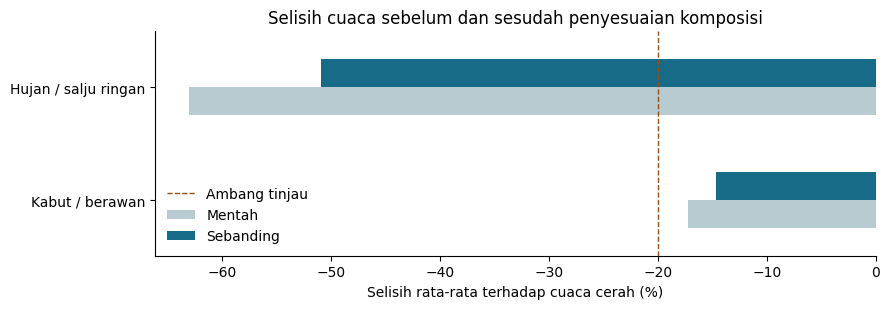

In [12]:
def weather_comparison(daily, min_days=3):
    """Bandingkan tiap kategori cuaca dengan cerah pada kelompok sebanding.

    Tiap kelompok adalah kombinasi tahun, musim, dan tipe hari. Kedua
    rata-rata ditimbang dengan jumlah hari kategori pembanding dalam kelompok.
    """
    strata = ["yr", "season", "workingday"]
    by_weather = daily.groupby("weathersit")["cnt"].agg(hari="size", rata_rata="mean")
    cells = daily.groupby([*strata, "weathersit"])["cnt"].agg(hari="size", rata_rata="mean")
    clear_mean = by_weather["rata_rata"].get(1, float("nan"))
    results = []
    for code, raw in by_weather.iterrows():
        if code == 1:
            continue
        comparable = cells.xs(code, level="weathersit").add_suffix("_cuaca")
        if 1 in by_weather.index:
            clear = cells.xs(1, level="weathersit").add_suffix("_cerah")
            comparable = comparable.join(clear, how="inner")
            comparable = comparable[
                comparable["hari_cuaca"].ge(min_days) & comparable["hari_cerah"].ge(min_days)
            ]
        else:
            comparable = comparable.iloc[0:0]
        weights = comparable["hari_cuaca"]
        supported = int(weights.sum())
        adjusted_clear = adjusted_weather = float("nan")
        if supported:
            adjusted_clear = comparable["rata_rata_cerah"].dot(weights) / supported
            adjusted_weather = comparable["rata_rata_cuaca"].dot(weights) / supported
        results.append({
            "weathersit": code,
            "selisih_mentah_pct": 100 * (raw["rata_rata"] / clear_mean - 1),
            "kelompok": len(comparable),
            "hari_tercakup": supported,
            "hari_kategori": int(raw["hari"]),
            "cakupan_pct": 100 * supported / raw["hari"],
            "cerah_sebanding": adjusted_clear,
            "cuaca_sebanding": adjusted_weather,
            "selisih_sebanding_pct": 100 * (adjusted_weather / adjusted_clear - 1),
        })
    return pd.DataFrame(results)


weather = day.groupby("weathersit").agg(
    cuaca=("cuaca", "first"), hari=("cnt", "size"), rata_rata=("cnt", "mean")
)
weather["selisih_pct"] = 100 * (weather["rata_rata"] / weather.loc[1, "rata_rata"] - 1)
display(weather.round(2))

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.barh(weather["cuaca"], weather["rata_rata"], color=["#176B87", "#438990", "#849DA0"])
ax.bar_label(bars, labels=[f"{angka(row.rata_rata, 1)}  (n={row.hari})"
                          for row in weather.itertuples()], padding=7)
ax.invert_yaxis()
ax.set(xlim=(0, weather["rata_rata"].max() * 1.31), xlabel="Rata-rata sewa per hari",
       title="Rata-rata penyewaan lebih rendah pada kategori hujan atau salju ringan")
fig.tight_layout()
plt.show()

matched = weather_comparison(day).set_index("weathersit")
matched["layak_ditinjau"] = matched["selisih_sebanding_pct"].le(-20) & matched["cakupan_pct"].ge(70)
weather_detail = matched.join(weather[["cuaca"]])
display(weather_detail.set_index("cuaca").round(1))

sensitivity = pd.concat([
    weather_comparison(day, min_days=minimum).assign(minimum_per_kategori=minimum)
    for minimum in (1, 3, 5)
])
display(sensitivity[["weathersit", "minimum_per_kategori", "kelompok", "hari_tercakup",
                     "hari_kategori", "cakupan_pct", "selisih_sebanding_pct"]].round(1))

plot_weather = weather_detail.set_index("cuaca")[
    ["selisih_mentah_pct", "selisih_sebanding_pct"]
].rename(columns={"selisih_mentah_pct": "Mentah", "selisih_sebanding_pct": "Sebanding"})
ax = plot_weather.plot.barh(figsize=(9, 3.2), color=["#B8CBD0", "#176B87"])
ax.axvline(-20, linestyle="--", color="#9A4C16", linewidth=1, label="Ambang tinjau")
ax.set(xlabel="Selisih rata-rata terhadap cuaca cerah (%)", ylabel="",
       title="Selisih cuaca sebelum dan sesudah penyesuaian komposisi")
sns.despine(ax=ax)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

- **Jam sibuk.** Pukul **08.00, 17.00, dan 18.00** pada hari kerja serta **12.00, 13.00, dan 14.00** pada hari nonkerja tetap masuk tiga besar pada setiap pemeriksaan. Tim bisa menyiapkan sepeda sebelum jam-jam ini.
- **Kabut atau berawan.** Setelah membandingkan hari yang sebanding, volume **14,6% lebih rendah** daripada saat cerah. Seluruh 247 hari bisa dibandingkan, tetapi selisihnya belum mencapai ambang 20%.
- **Hujan atau salju ringan.** Volume **50,9% lebih rendah**, tetapi hanya **10 dari 21 hari** yang bisa dibandingkan pada aturan utama. Syarat satu hari memasukkan semua 21 hari, dengan pembanding yang lebih sedikit di tiap kelompok. Syarat lima hari hanya memasukkan 7 hari. Karena rekomendasi berubah saat syarat dilonggarkan, gunakan hasil utama untuk memprioritaskan pengumpulan data tambahan.

Hari pada kelompok yang sama masih bisa berbeda, misalnya dari sisi suhu, acara setempat, atau gangguan layanan. Angka ini menunjukkan perbedaan volume yang tercatat. Data harian juga tidak memiliki hari berkategori cuaca berat.

## Analisis Lanjutan (Opsional)

**Pertanyaan 3 — Kapan promosi pengguna kasual layak diuji?**

Selama 2011–2012, pada blok jam nonkerja mana pengguna kasual paling sering menyewa? Bagaimana rata-ratanya jika dibandingkan dengan blok yang sama pada hari kerja? Blok tersebut menjadi kandidat promosi jika minimal 30% transaksinya berasal dari pengguna kasual pada **masing-masing tahun**.

1. **Bagi jam menjadi lima blok.** Kode `pd.cut()` mengubah angka jam menjadi label. Contohnya, pukul 11.00 masuk blok `10–15`, yang berarti pukul 10.00 sampai 15.59.
2. **Hitung rata-rata sewa kasual per jam tercatat.** Jumlahkan sewa kasual, lalu bagi dengan jumlah catatan jam dalam blok. Pembagian ini membuat blok yang panjangnya berbeda bisa dibandingkan.
3. **Pilih blok nonkerja dengan rata-rata tertinggi.** Fungsi `idxmax()` mencari label blok yang nilainya paling tinggi. Bandingkan hasilnya dengan blok yang sama pada hari kerja.
4. **Cek batas 30% pada setiap tahun.** Porsi kasual dihitung dengan membagi jumlah sewa kasual dengan jumlah seluruh sewa. Lihat kolom `lolos_ambang` untuk hasil 2011 dan 2012.


sewa  slot  rata_rata  kasual_per_slot  porsi_kasual_pct  \
blok  tipe_hari                                                               
00–05 Kerja       47859  2912       16.4              2.7              16.4   
      Nonkerja    58650  1364       43.0              8.4              19.5   
06–09 Kerja      551372  1984      277.9             15.8               5.7   
      Nonkerja    78370   922       85.0             19.5              22.9   
10–15 Kerja      535932  2983      179.7             40.8              22.7   
      Nonkerja   469779  1386      338.9            120.8              35.6   
16–19 Kerja      827021  1994      414.8             49.2              11.9   
      Nonkerja   274148   922      297.3             97.6              32.8   
20–23 Kerja      330226  1992      165.8             22.2              13.4   
      Nonkerja   119322   920      129.7             32.5              25.1   

                 porsi_volume_pct  
blok  tipe_hari                    
00–05 Kerja                   2.1  
      Nonkerja                5.9  
06–09 Kerja                  24.1  
      Nonkerja                7.8  
10–15 Kerja                  23.4  
      Nonkerja               47.0  
16–19 Kerja                  36.1  
      Nonkerja               27.4  
20–23 Kerja                  14.4  
      Nonkerja               11.9

Range jam teratas pada hari nonkerja: 10–15


,Tipe hari,Sewa kasual per jam tercatat
0,Nonkerja,120.8
1,Kerja,40.8


Selisih: 80,0 sewa kasual per jam tercatat.


,slot,kasual_per_slot,porsi_kasual_pct,lolos_ambang
Tahun,,,,
2011,690,96.3,37.1,True
2012,696,145.0,34.7,True


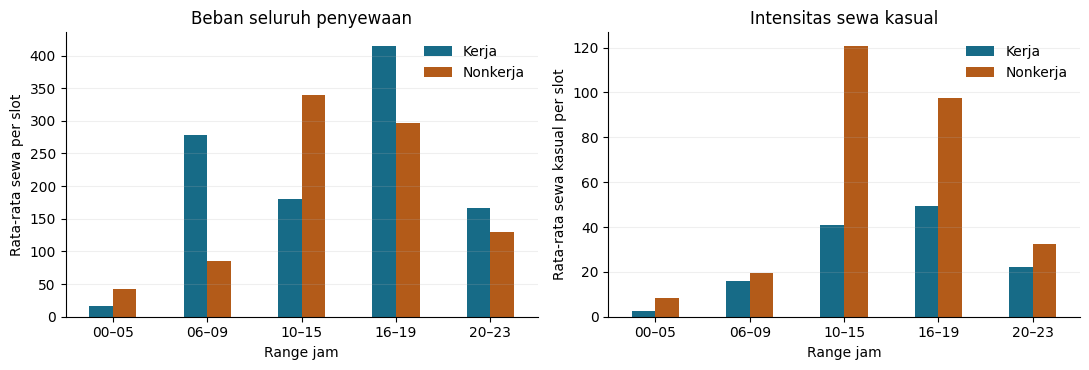

In [15]:
BLOCKS = ["00–05", "06–09", "10–15", "16–19", "20–23"]


def assign_blocks(hours):
    """Jam lokal dibagi menjadi lima blok operasional."""
    return pd.cut(hours, [-1, 5, 9, 15, 19, 23], labels=BLOCKS)


def rental_segments(hourly, keys):
    """Ringkas volume dan komposisi sewa per slot jam tercatat."""
    segments = hourly.groupby(keys, observed=True).agg(
        sewa=("cnt", "sum"),
        slot=("cnt", "size"),
        kasual=("casual", "sum"),
    )
    segments["rata_rata"] = segments["sewa"] / segments["slot"]
    segments["kasual_per_slot"] = segments["kasual"] / segments["slot"]
    segments["porsi_kasual_pct"] = 100 * segments["kasual"] / segments["sewa"]
    return segments


# 1. Masukkan tiap jam ke salah satu dari lima blok.
hour["blok"] = assign_blocks(hour["hr"])
assert hour["blok"].notna().all()
# 2. Hitung rata-rata per jam tercatat dan porsi kasual untuk tiap blok.
segments = rental_segments(hour, ["blok", "tipe_hari"])
segments["porsi_volume_pct"] = 100 * segments["sewa"] / segments.groupby("tipe_hari")["sewa"].transform("sum")
display(segments.drop(columns="kasual").round(1))

# 3. Pilih range nonkerja teratas, lalu bandingkan dengan blok yang sama pada hari kerja.
nonwork_segments = segments.xs("Nonkerja", level="tipe_hari")
target_block = nonwork_segments["kasual_per_slot"].idxmax()
target = nonwork_segments.loc[target_block]
work_reference = segments.loc[(target_block, "Kerja")]
comparison = pd.DataFrame({
    "Tipe hari": ["Nonkerja", "Kerja"],
    "Sewa kasual per jam tercatat": [target.kasual_per_slot, work_reference.kasual_per_slot],
})
print(f"Range jam teratas pada hari nonkerja: {target_block}")
display(comparison.round(1))
difference = target.kasual_per_slot - work_reference.kasual_per_slot
print(f"Selisih: {angka(difference, 1)} sewa kasual per jam tercatat.")

# 4. Cek apakah porsi kasual mencapai 30% pada masing-masing tahun.
annual_segments = rental_segments(hour, ["yr", "blok", "tipe_hari"])
annual_target = annual_segments.xs((target_block, "Nonkerja"), level=["blok", "tipe_hari"]).copy()
annual_target.index = annual_target.index + 2011
annual_target.index.name = "Tahun"
annual_target["lolos_ambang"] = annual_target["porsi_kasual_pct"].ge(30)
display(annual_target[["slot", "kasual_per_slot", "porsi_kasual_pct", "lolos_ambang"]].round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, metric, title, ylabel in [
    (axes[0], "rata_rata", "Beban seluruh penyewaan", "Rata-rata sewa per slot"),
    (axes[1], "kasual_per_slot", "Intensitas sewa kasual", "Rata-rata sewa kasual per slot"),
]:
    segments[metric].unstack().reindex(BLOCKS).plot.bar(ax=ax, color=COLORS, rot=0)
    ax.set(title=title, xlabel="Range jam", ylabel=ylabel)
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

**Insight:** (Opsional)

Pada hari nonkerja, blok **10.00–15.59** paling ramai untuk pengguna kasual, dengan **120,8 sewa kasual per jam tercatat**. Pada jam yang sama di hari kerja, angkanya **40,8**. Porsi transaksi kasual mencapai **37,1% pada 2011** dan **34,7% pada 2012**, sehingga melampaui ambang 30% pada kedua tahun. Promosi bisa diuji pada jam ini jika tersedia cukup sepeda untuk dipinjam dan cukup tempat kosong untuk mengembalikan sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Prioritaskan persiapan sepeda sebelum pukul **08.00 dan 17.00** pada hari kerja, serta sebelum pukul **12.00** pada hari nonkerja. Puncak tertinggi terjadi pukul **17.00** pada hari kerja (525,3 sewa per jam tercatat) dan pukul **13.00** pada hari nonkerja (372,7). Selisihnya **4 jam** dan **152,6 sewa per jam tercatat**.
- **Conclusion pertanyaan 2:** Dibanding rata-rata hari cerah, selisih langsung adalah **−17,2%** untuk kabut atau berawan dan **−63,0%** untuk hujan atau salju ringan. Setelah memakai kelompok hari sebanding, selisihnya **−14,6%** dan **−50,9%**. Kabut belum mencapai ambang penurunan. Hujan ringan belum mencapai ambang cakupan. Kumpulkan lebih banyak catatan sebelum mengubah penempatan petugas secara rutin.
- **Conclusion pertanyaan 3:** Uji promosi kasual pada hari nonkerja pukul **10.00–15.59**. Rata-rata sewa kasualnya **120,8 per jam tercatat**, sekitar tiga kali volume pada jam yang sama di hari kerja (**40,8**). Porsinya melampaui ambang 30% pada kedua tahun.

**Rekomendasi Action Item:**

| Tim | Yang dilakukan selama empat minggu | Cara menilai hasil |
| --- | --- | --- |
| Redistribusi | Periksa stasiun sebelum jam sibuk. Isi ulang sepeda di stasiun yang hampir kosong dan siapkan ruang di stasiun yang hampir penuh. | Bandingkan menit stasiun kosong atau penuh dengan empat minggu sebelumnya pada tipe hari yang sama. |
| Operasi | Tambah catatan volume, jumlah petugas, dan ketersediaan sepeda saat cuaca memburuk. Prioritaskan hari hujan ringan karena cakupan datanya masih rendah. | Tinjau penempatan petugas ketika perbandingan memenuhi ambang penurunan dan cakupan. Pantau juga kualitas layanan di stasiun. |
| Pemasaran | Uji promosi pengguna kasual pukul 10.00–15.59 pada hari nonkerja di stasiun yang punya persediaan cukup. Pilih stasiun atau hari serupa tanpa promosi sebagai pembanding. | Ukur sewa kasual tambahan dan biaya untuk tiap sewa tambahan. Perluas uji jika sewa bertambah dengan biaya yang dapat diterima dan layanan tetap baik. |